# Bike Sharing Case Study, Part 4: A Natural-Language Prototype for Operations

**Brief:** *"Design a prototype to help the operations manager use the model output through natural language questions for understanding demand."*

## 1. Who it's for and what they ask

The operations manager plans staff, rebalancing trucks and maintenance. They don't want a notebook; they want to ask:

| Kind of question | Example | Answered by |
|---|---|---|
| **Plan a specific day** | "How many bikes do we need next Friday at 6pm if it rains?" | `forecast_day` |
| **What-if** | "How much does rain change demand on 14 June compared to clear weather?" | `forecast_day` × 2 |
| **Understand patterns** | "What are the busiest hours on weekends?" · "How does weather affect rentals?" | `historical_demand` |
| **Strategic** | "Do we need to buy more bikes?" | `fleet_summary` |

## 2. Design principles

1. **Every number comes from a tool, never from the language layer.** The language layer only *understands the question* and *phrases the answer*. This removes the main risk of LLM assistants: confident, made-up numbers.
2. **Show your working.** Each answer has a "How this was computed" panel with the exact tool call, and the data table behind it, so the manager (or an analyst) can check it.
3. **State the assumptions that matter** in the answer itself: 2012 demand levels, the 90 % planning level, typical temperature when none is given, heavy rain being rare in training data.
4. **Works without an API key.** A rule-based parser handles the common question shapes offline. A **LangGraph agent with Gemini** is an optional upgrade for free-form phrasing and follow-ups.
5. **Same logic as the model notebook.** Features and assumptions come from `bike_model.py`; the trained models from `Model/bike_demand.joblib`.

## 3. Architecture

```
 Operations manager
        │  question in plain English
        ▼
 ┌─────────────────────────────┐      offline: regex parser (dates, weather, hour, temp, growth)
 │  Language layer             │  or  gemini:  LangGraph agent, Gemini via LangChain, chooses tools
 └─────────────┬───────────────┘
               │  tool call with structured arguments
               ▼
 ┌─────────────────────────────┐
 │  Tools (demand_assistant.py)│  forecast_day · historical_demand · fleet_summary
 └─────────────┬───────────────┘
               │  uses
               ▼
   Part 3 models (members, casual, calibrated 90% bikes-in-use) + hour.csv history
               │
               ▼
   Answer text + data table + chart + the exact tool calls   ──►  Streamlit chat app (app.py)
```

**Files:**
- `demand_assistant.py`: tools, offline parser, LangGraph + Gemini agent
- `app.py`: Streamlit chat interface
- `bike_model.py`, `Model/bike_demand.joblib`: from Part 3

In [1]:
import inspect
from datetime import date
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import demand_assistant as da

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
TODAY = date(2026, 11, 4)  # fixed so the demo is reproducible; the app uses the real date

def demo(question):
    a = da.answer_offline(question, TODAY)
    print(f"Q: {question}\n")
    print(a.text)
    print("\ntool calls:", "; ".join(f"{n}({', '.join(f'{k}={v!r}' for k, v in args.items())})" for n, args in a.calls))
    print("=" * 100)
    return a

## 4. Demo: the four kinds of question (offline mode)

In [2]:
a1 = demo("How many bikes do we need next Friday at 6pm if it rains?")
a2 = demo("How much does rain change demand on 14 June compared to clear weather?")
a3 = demo("Forecast for Saturday at 2pm, 30 degrees and sunny with 20% growth")
a4 = demo("What's the demand on Christmas Day, 25 December, 2 degrees?")

Q: How many bikes do we need next Friday at 6pm if it rains?

**Friday 06 November 2026** (working day, rain, 16.4°C typical for the month)
- At **18:00**: about **436** rentals; plan for **136 bikes on the road** (expected 97).
- Busiest hour: **08:00**, plan for **153 bikes on the road** (59% of the fleet's design capacity of 259).
- Whole day: about **5,180** rentals.

_Assumptions: 90% plan = demand stays below this 9 hours out of 10; model trained on 2011-2012, so this is at 2012 demand levels; add a growth % if demand has grown._

tool calls: forecast_day(date_str='2026-11-06', weather='rain', temp_c=None, holiday=False, growth_pct=0)
Q: How much does rain change demand on 14 June compared to clear weather?

**Monday 14 June 2027** (working day, rain, 29.5°C typical for the month)
- Busiest hour: **17:00**, plan for **218 bikes on the road** (84% of the fleet's design capacity of 259).
- Whole day: about **6,216** rentals.

_Assumptions: 90% plan = demand stays below this 9 hours

Notes on these answers:
- **Friday 6pm in rain:** plan for 136 bikes on the road at 18:00, well within the fleet's design capacity, so no action needed beyond normal rebalancing.
- **Rain vs clear on 14 June:** rain cuts the day's rentals by about 11 % and the peak by about 17 bikes.
- **Hot Saturday with 20 % growth:** the peak (~330 bikes) goes **above** the current design capacity (259). This is exactly the kind of day the assistant should flag. Weekend afternoons with long leisure trips are a pressure window.
- **Christmas:** recognised automatically as a federal holiday, so the model treats it as a non-working day.

In [3]:
a5 = demo("What are the busiest hours on weekends?")
a6 = demo("How does weather affect rentals?")
a7 = demo("Do we need to buy more bikes?")
a7.table

Q: What are the busiest hours on weekends?

**Average rentals per hour by hour** (2011–2012, day type: weekend/holiday; 5,514 hours):
- Highest: **13:00** (373), **12:00** (366), **14:00** (365)
- Lowest: **04:00** (8)
- Overall average: 181 per hour.

tool calls: historical_demand(by='hr', metric='rentals', day_type='weekend/holiday', weather=None, season=None, year=None)
Q: How does weather affect rentals?

**Average rentals per hour by weather** (2011–2012, all days; 17,379 hours):
- **Clear**: 205
- **Mist/Cloudy**: 175
- **Light rain/snow**: 112
- **Heavy rain/snow**: 74
- Overall average: 189 per hour.

tool calls: historical_demand(by='weathersit', metric='rentals', day_type=None, weather=None, season=None, year=None)
Q: Do we need to buy more bikes?

**Recommended fleet: about 720 bikes** (600-1,100 depending on trip length and parked-bike buffer).
- That covers **259 bikes on the road at once** on 95% of days, plus parked bikes and repairs.
- In 2012 an average of only **59** 

,days covered,design peak (on road),total fleet,days over capacity / yr,of which weekends/holidays,extra bikes vs 80%
0,75%,238,661,92,39,-9
1,80%,241,670,73,37,0
2,90%,249,691,37,26,21
3,95%,259,719,19,18,49
4,99%,279,776,4,4,106
5,100%,283,787,0,0,117


### What the manager sees for a forecast
The app draws this chart for every single-day answer: the 90 % planning level for each hour against the fleet's design capacity.

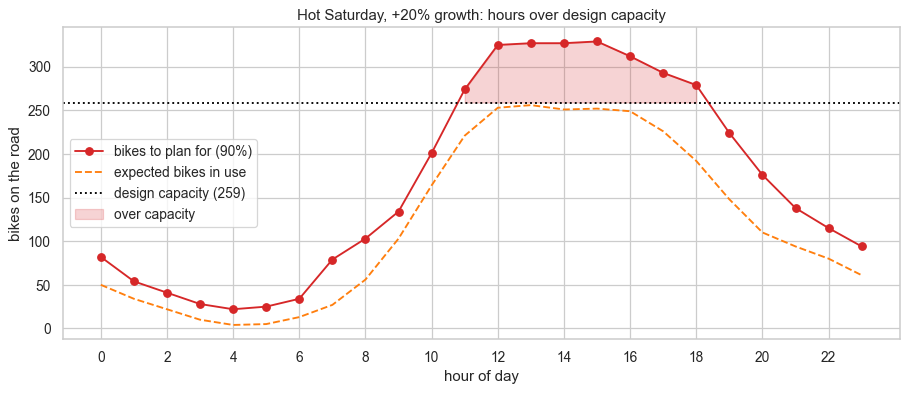

In [4]:
t = a3.table
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(t.hour, t["bikes to plan for (90%)"], marker="o", color="tab:red", label="bikes to plan for (90%)")
ax.plot(t.hour, t["bikes in use (expected)"], ls="--", color="tab:orange", label="expected bikes in use")
ax.axhline(da.DESIGN_IN_USE, color="black", ls=":", label=f"design capacity ({da.DESIGN_IN_USE})")
ax.fill_between(t.hour, da.DESIGN_IN_USE, t["bikes to plan for (90%)"],
                where=t["bikes to plan for (90%)"] > da.DESIGN_IN_USE, color="tab:red", alpha=0.2, label="over capacity")
ax.set(title="Hot Saturday, +20% growth: hours over design capacity", xlabel="hour of day", ylabel="bikes on the road",
       xticks=range(0, 24, 2))
ax.legend()
plt.show()

## 5. Does the parser understand questions it wasn't built around?

The examples above were used while building the parser, so they flatter it. Below are **new phrasings** written afterwards, each labelled with the tool and the key arguments a correct answer needs. A question counts as correct only if the tool **and** every labelled argument match.

In [5]:
tests = [
    ("bikes needed on the 3rd of July", "forecast_day", {"date_str": "2027-07-03"}),
    ("expected usage for Monday morning rush when it's foggy", "forecast_day", {"weather": "cloudy", "_hour": 8}),
    ("what happens to demand at 17:30 tomorrow if there's a thunderstorm", "forecast_day", {"weather": "heavy rain", "_hour": 17, "date_str": "2026-11-05"}),
    ("plan for Thanksgiving, November 26", "forecast_day", {"date_str": "2026-11-26"}),
    ("how busy will this Sunday be if it's 12 degrees", "forecast_day", {"date_str": "2026-11-08", "temp_c": 12.0}),
    ("Saturday 1pm rain versus dry, what's the difference", "forecast_day", {"weather": "rain", "_compare": True}),
    ("2027-04-10 at 9am with 15% more riders", "forecast_day", {"date_str": "2027-04-10", "_hour": 9, "growth_pct": 15}),
    ("Is our fleet big enough?", "fleet_summary", {}),
    ("Are bikes sitting idle too much?", "fleet_summary", {}),
    ("Should we purchase extra bicycles?", "fleet_summary", {}),
    ("When do commuters ride the most?", "historical_demand", {"by": "hr", "day_type": "working day"}),
    ("Which day of the week is quietest?", "historical_demand", {"by": "weekday"}),
    ("average rentals per month in 2011", "historical_demand", {"by": "mnth", "year": 2011}),
    ("how do seasons compare", "historical_demand", {"by": "season"}),
    ("typical bikes on the road by hour during summer", "historical_demand", {"by": "hr", "metric": "bikes in use", "season": "summer"}),
    ("do people ride less on rainy weekends?", "historical_demand", {"weather": "rain", "day_type": "weekend/holiday"}),
    ("weekdays vs weekends, which is busier?", "historical_demand", {"by": "workingday"}),
    ("what's the weather like in Paris?", None, {}),
    ("tell me a joke", None, {}),
    # harder, more natural phrasings
    ("bikes needed at noon on Friday", "forecast_day", {"date_str": "2026-11-06", "_hour": 12}),
    ("if it pours on the morning of the 5th, are we OK?", "forecast_day", {"date_str": "2026-11-05", "weather": "rain"}),
    ("and what if it's sunny instead?", "forecast_day", {"weather": "clear"}),  # follow-up: needs the previous question
    ("how many bikes will be out during the Easter weekend?", "forecast_day", {"date_str": "2027-03-27"}),
    ("is the evening crunch worse in winter?", "historical_demand", {"season": "winter"}),
]

rows = []
for q, want_tool, want_args in tests:
    tool, args = da.route(q, TODAY)
    args = args if isinstance(args, dict) else {}
    wrong = [k for k, v in want_args.items() if args.get(k) != v]
    ok = tool == want_tool and not wrong
    rows.append({"question": q, "expected": want_tool, "got": tool, "correct": ok,
                 "mismatched args": ", ".join(f"{k}: got {args.get(k)!r}" for k in wrong) if tool == want_tool else ""})
results = pd.DataFrame(rows)
core, hard = results.iloc[:19], results.iloc[19:]
print(f"Standard phrasings: {core.correct.sum()} / {len(core)} correct")
print(f"Harder phrasings  : {hard.correct.sum()} / {len(hard)} correct")
results

Standard phrasings: 19 / 19 correct
Harder phrasings  : 0 / 5 correct


,question,expected,got,correct,mismatched args
0,bikes needed on the 3rd of July,forecast_day,forecast_day,True,
1,expected usage for Monday morning rush when it...,forecast_day,forecast_day,True,
2,what happens to demand at 17:30 tomorrow if th...,forecast_day,forecast_day,True,
3,"plan for Thanksgiving, November 26",forecast_day,forecast_day,True,
4,how busy will this Sunday be if it's 12 degrees,forecast_day,forecast_day,True,
5,"Saturday 1pm rain versus dry, what's the diffe...",forecast_day,forecast_day,True,
6,2027-04-10 at 9am with 15% more riders,forecast_day,forecast_day,True,
7,Is our fleet big enough?,fleet_summary,fleet_summary,True,
8,Are bikes sitting idle too much?,fleet_summary,fleet_summary,True,
9,Should we purchase extra bicycles?,fleet_summary,fleet_summary,True,


**Reading this honestly:**
- The standard phrasings were written by the same person who wrote the parser, after seeing its rules, so they're an optimistic test.
- The harder phrasings show where a rule-based parser breaks: words like *noon*, dates without a month (*the 5th*), follow-ups that depend on the previous question, and named events (*Easter*).
- That's the case for **Gemini mode** (section 6), which reads free-form language and keeps conversation context, while the tools still produce every number.
- A proper evaluation would use real questions logged from the operations team.

## 6. Gemini mode: a LangGraph agent for free-form phrasing

A rule-based parser is transparent and free, but brittle: it only knows the phrasings someone wrote rules for, and it can't handle follow-ups ("and if it rains?"). **Gemini mode** replaces the parser with an agent built in **LangGraph**, using **Gemini** through LangChain (`langchain-google-genai`), and keeps exactly the same tools.

**The graph:**
```
START ──► agent ──(tool calls?)──► tools ──┐
            ▲                               │
            └───────────────────────────────┘
          agent ──(no tool calls)──► END
```
- **`agent` node:** Gemini, with the three tools bound (`llm.bind_tools`), plus the system prompt. It either asks for tools or writes the final answer.
- **`tools` node:** LangGraph's `ToolNode` runs the requested tools locally, in parallel if there are several. Each tool is a LangChain `@tool` whose schema comes from its type hints and docstring, so Gemini sees allowed values like `weather ∈ {clear, cloudy, rain, heavy rain}`.
- **`tools_condition`:** routes back to `tools` while the model keeps asking for them, otherwise to `END`.
- **Memory:** an `InMemorySaver` checkpointer stores each chat under a `thread_id`, so "and if it's sunny instead?" knows which day was meant.

**Guardrails built in:**
- The system prompt forbids numbers that didn't come from a tool and lists the caveats to mention.
- `ToolNode(handle_tool_errors=True)`: bad arguments go back to Gemini as an error message so it can correct itself, rather than crashing.
- The recursion limit (12 steps) caps the agent ↔ tools loop.
- Temperature 0 for consistent answers.
- If the key is missing or the API fails, the app falls back to offline mode and says so.
- The model is configurable: `GEMINI_MODEL` (default `gemini-3.5-flash`). Any LangChain chat model with tool calling can be swapped in via `build_agent(llm=...)`.

**To enable it:**
```
pip install langgraph langchain-google-genai
set GOOGLE_API_KEY=...            (a Gemini API key from Google AI Studio)
streamlit run app.py              then choose "Gemini (LangGraph agent)" in the sidebar
```

In [6]:
print(da.SYSTEM_PROMPT)
print()
for t in da.make_lc_tools():
    print(f"{t.name}: {list(t.args)}")
print()
print(inspect.getsource(da.build_agent))

You help the operations manager of a city bike-sharing company understand demand.

Use the tools for every number you give. Never estimate, extrapolate, or recall figures yourself; if no tool can answer, say what you can answer instead.

Context:
- The model was trained on Washington D.C. Capital Bikeshare data from 2011-2012. Forecasts for later dates are at 2012 demand levels unless the user gives a growth percentage; say so.
- "Bikes to plan for (90%)" means demand stays below this level 9 hours out of 10.
- Bikes in use assumes 12-minute member trips and 30-minute casual trips.
- The recommended fleet (~720 bikes, range 600-1,100) covers 95% of days; utilisation is low and pressure is concentrated in working-day evenings and weekend afternoons.
- When the user gives no temperature, the tool uses the typical temperature for that month.
- Heavy rain occurred in only 3 training hours, so flag such forecasts as rough.

Answer in a few short bullet points: the number first, then the one

### Running the graph without an API key

To show the graph really works (routing, parallel tool calls, error recovery and memory) without a Gemini key, we plug in a **scripted stand-in model**: LangChain's fake chat model replays fixed replies. Everything else is the real code path: the real tools, `ToolNode`, routing and checkpointer. The replies are scripted, so this tests the **plumbing**, not Gemini's understanding.

Script:
- **Turn 1:** two parallel `forecast_day` calls (rain vs clear), then an answer.
- **Turn 2, a follow-up in the same thread:** first a call with an invalid argument, which must come back as an error; then a corrected call, then an answer.

In [7]:
from langchain_core.language_models.fake_chat_models import GenericFakeChatModel
from langchain_core.messages import AIMessage

class ScriptedLLM(GenericFakeChatModel):
    def bind_tools(self, tools, **kw):  # the stand-in ignores tool schemas
        return self

script = iter([
    AIMessage(content="", tool_calls=[
        {"name": "forecast_day", "args": {"date_str": "2026-11-06", "weather": "rain"}, "id": "c1"},
        {"name": "forecast_day", "args": {"date_str": "2026-11-06", "weather": "clear"}, "id": "c2"}]),
    AIMessage(content="(scripted) Rain lowers Friday's peak; see the table."),
    AIMessage(content="", tool_calls=[{"name": "historical_demand", "args": {"by": "nonsense"}, "id": "c3"}]),
    AIMessage(content="", tool_calls=[{"name": "historical_demand", "args": {"by": "hr", "day_type": "weekend/holiday"}, "id": "c4"}]),
    AIMessage(content="(scripted) Weekends peak around 13:00."),
])
agent = da.build_agent(llm=ScriptedLLM(messages=script))
print(agent.get_graph().draw_mermaid())  # the compiled graph, as LangGraph sees it

t1 = da.answer_gemini("Next Friday: rain vs clear?", thread_id="demo", today=TODAY, agent=agent)
t2 = da.answer_gemini("And what are the busiest weekend hours?", thread_id="demo", today=TODAY, agent=agent)
history = agent.get_state({"configurable": {"thread_id": "demo"}}).values["messages"]

print("turn 1 tool calls:", t1.calls)
print("turn 2 tool calls:", t2.calls, " (the failed call is filtered out)")
print("error sent back to the model:", [m.content[:90] for m in history if getattr(m, "status", None) == "error"])
print("messages remembered in thread 'demo':", len(history))
t1.table.head(10)

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	agent(agent)
	tools(tools<hr/><small><em>__tools = forecast_day, historical_demand, fleet_summary</em></small>)
	__end__([<p>__end__</p>]):::last
	__start__ --> agent;
	agent -.-> __end__;
	agent -.-> tools;
	tools --> agent;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc

turn 1 tool calls: [('forecast_day', {'date_str': '2026-11-06', 'weather': 'rain'}), ('forecast_day', {'date_str': '2026-11-06', 'weather': 'clear'})]
turn 2 tool calls: [('historical_demand', {'by': 'hr', 'day_type': 'weekend/holiday'})]  (the failed call is filtered out)
error sent back to the model: ['Error: ToolInvocationError("Error invoking tool \'historical_demand\' with kwargs {\'by\': \'no']
messages remembered in thread 'demo': 11


,hour,plan: 2026-11-06 rain,plan: 2026-11-06 clear
0,0,17,21
1,1,11,13
2,2,9,10
3,3,7,8
4,4,7,8
5,5,12,14
6,6,32,46
7,7,92,111
8,8,153,173
9,9,88,103


## 7. Running the prototype

```
streamlit run app.py
```

The app opens in the browser with:
- a chat box and clickable example questions
- the recommended fleet in the sidebar
- for each answer: the text, an hourly chart against design capacity, the data table, and the exact tool calls

## 8. Limitations and next steps

| Limitation | Next step |
|---|---|
| Offline parser only knows common phrasings (see the score above) | Use Gemini mode; log unanswered questions to grow the test set and evaluate Gemini on it |
| Forecasts use typical weather for the month unless told otherwise | Connect a weather forecast API so "tomorrow" uses the real forecast |
| City-wide only, so it can't say *which* stations will run out | Add station-level data and a `forecast_station` tool |
| Trained on 2011–2012; growth is a manual input | Retrain on recent data; track forecast error weekly |
| No memory of what operations actually did | Log rebalancing actions and outcomes, the data needed for the Part 2 experiment |